In [10]:
import jax
import jax.numpy as jnp 
import WDM
import WDM_LISAresponse
import numpy as np
import matplotlib.pyplot as plt
from WDM_LISAresponse.code.lisa_response.time_domain_response import basis_tensors
from WDM_LISAresponse.code.lisa_response.response import one_arm_response_td, one_arm_response_freq_domain, one_arm_response_wdm
import time 
from lisaorbits.file import read_orbit_file
from lisaorbits import InterpolatedOrbits
from scipy.signal.windows import tukey


year_SI = 3.154e7

key = jax.random.PRNGKey(0)

In [11]:
def waveform_polarisations(time, A_plus, A_cross, f, phi_0):
    """
    This is for a sine wave signal.

    Parameters
    ----------
    time : ndarray
        time in the solar system barycenter [s]
    A_plus : float
        plus polarisation amplitude [strain]
    A_cross : float
        cross polarisation amplitude [strain]
    f : float
        GW frequency [Hz]
    phi_0 : float
        phase angle [rad]

    Returns
    -------
    h_plus : ndarray
        plus polarised signal, shaped like time.
    h_cross : ndarray
        cross polarised signal, shaped like time.
    """
    h_plus = A_plus * np.cos(2*np.pi*f*time+phi_0)
    h_cross = A_cross * np.sin(2*np.pi*f*time+phi_0)
    return h_plus, h_cross

In [12]:
theta, phi = jnp.array(1.0), jnp.array(1.0)
basis_tensors(theta, phi)

num_points = 100

key, subkey = jax.random.split(key)
theta = jax.random.uniform(key, shape=(num_points,), minval=0.0, maxval=jnp.pi)

key, subkey = jax.random.split(key)
phi = jax.random.uniform(key, shape=(num_points,), minval=0.0, maxval=2*jnp.pi)
polarisation_basis=jnp.zeros((num_points,2, 3, 3))
t_start = time.time()
for i in jnp.arange(num_points):    
    polarisation_basis = polarisation_basis.at[i,:,:,:].set(basis_tensors(theta[i], phi[i]))
    polarisation_basis.block_until_ready()
t_end = time.time()

print(f"Computed {num_points} basis tensors in {t_end - t_start} seconds")

Computed 100 basis tensors in 0.14789485931396484 seconds


In [13]:
#Inject orbital data into our system

orbit_data = read_orbit_file('esa-trailing-orbits.h5')

orbit_times = orbit_data.t0 + orbit_data.dt * np.arange(orbit_data.size)
t_start = orbit_data.t0

orbits_trailing = InterpolatedOrbits(orbit_times, 
                                     orbit_data.positions, 
                                     orbit_data.velocities)

In [14]:
#waveform signal 

theta, phi, A_plus, A_cross, f, phi_0 = np.pi/2, 0.0, 5e-22, 0.0, 3.0e-3, 0.0

t_start = orbit_data.t0+year_SI
#t_end = t_start + 0.001*year_SI
times = np.arange(t_start, t_start+10*5000, 10)
h_plus_td, h_cross_td = waveform_polarisations(times, A_plus, A_cross, f, phi_0)
alpha = 0.05
N_tukey = len(times)
print("Lenght of array is", N_tukey)

w = tukey(N_tukey, alpha=alpha)

n_start = int(np.ceil(0.5*alpha * (N_tukey - 1)))
n_end = int(np.floor((1-alpha * 0.5) * (N_tukey - 1))) + 1

w_h_plus_td = w * h_plus_td
w_h_cross_td = w * h_cross_td

Lenght of array is 5000


Computed 5000 points in 0.11305689811706543 seconds using time domain
Computed 5000 points in 32.86492705345154 seconds using frequency domain


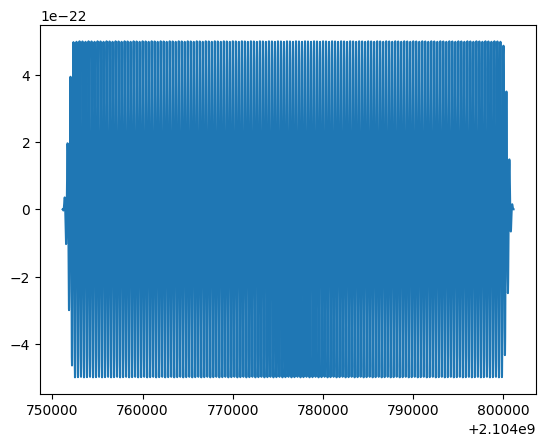

Current length of time series: 5000
WDM_transform(Nf=500, N=5000, q=1, d=4, A_frac=0.25, calc_m0=True)
self.Nt = 10 time cells
self.Nf = 500 frequency cells
self.dT = 5000.0 time resolution
self.dF = 0.0001 frequency resolution
self.K = 1000 window length
Padded length of time series: 5000
0.0


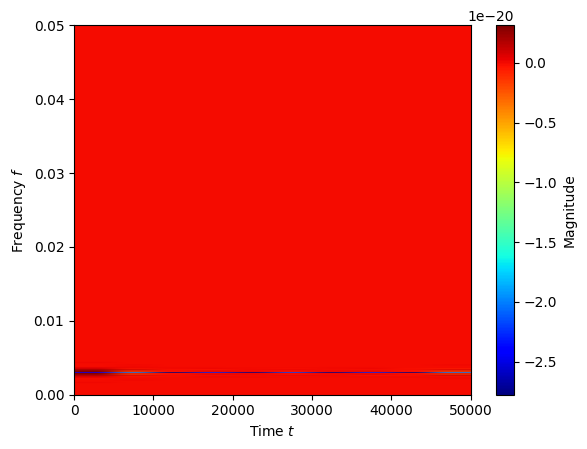

Computed 5000 points in 7.890522003173828 seconds using time-frequency domain


In [15]:
t_start_timer = time.time()
dl_sr = one_arm_response_td(times, 1, 2, orbits_trailing, theta, phi, w_h_plus_td, w_h_cross_td, num_int_points=100)
t_end_timer = time.time()
num_points = len(dl_sr)
print(f"Computed {num_points} points in {t_end_timer - t_start_timer} seconds using time domain")

t_start_timer = time.time()
dl_sr_freq = one_arm_response_freq_domain(times, 1, 2, orbits_trailing, theta, phi, w_h_plus_td, w_h_cross_td)
t_end_timer = time.time()
num_points = len(dl_sr_freq)
print(f"Computed {num_points} points in {t_end_timer - t_start_timer} seconds using frequency domain")

t_start_timer = time.time()
dl_sr_wdm = one_arm_response_wdm(times, 1, 2, orbits_trailing, theta, phi, w_h_plus_td, w_h_cross_td)
t_end_timer = time.time()
num_points = len(dl_sr_wdm)
print(f"Computed {num_points} points in {t_end_timer - t_start_timer} seconds using time-frequency domain")

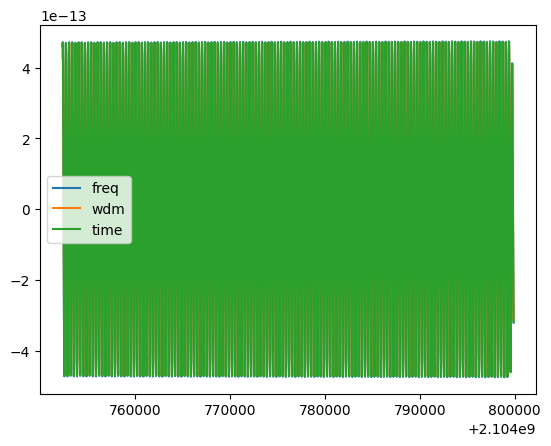

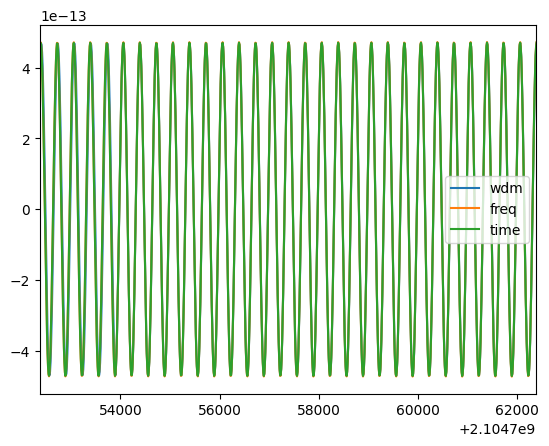

In [16]:
plt.plot(times[n_start:n_end], dl_sr_freq[n_start:n_end], label= "freq")
plt.plot(times[n_start:n_end], dl_sr_wdm[n_start:n_end]/ (4.0*np.pi), label="wdm")
plt.plot(times[n_start:n_end], dl_sr[n_start:n_end], label="time")
plt.legend()
plt.show()

plt.plot(times[n_start:n_end], dl_sr_wdm[n_start:n_end]/ (4.0*np.pi), label="wdm")
plt.plot(times[n_start:n_end], dl_sr_freq[n_start:n_end], label= "freq")
plt.plot(times[n_start:n_end], dl_sr[n_start:n_end], label="time")
plt.legend()
plt.xlim(times[n_start], times[n_start]+10000)
plt.show()

In [ ]:
#calculate mismatch

def compare_signals(h_ref, h_test):
    """
    h_ref  : reference signal (e.g. time-domain)
    h_test : signal to compare (e.g. FT or WDM)

    Returns
    -------
    result : dict with
      A           : best-fit complex scale factor
      res_L2      : L2 norm of residual ||h_ref - A h_test||
      ref_L2      : L2 norm of reference ||h_ref||
      rel_L2      : relative L2 error = res_L2 / ref_L2
      overlap     : normalized overlap (GW-style)
      mismatch    : 1 - overlap
    """
    h_ref  = np.asarray(h_ref)
    h_test = np.asarray(h_test)

    

  
    # L2 norms
    res = h_ref - h_test
    res_L2 = np.linalg.norm(res)
    ref_L2 = np.linalg.norm(h_ref) + 1e-30
    rel_L2 = res_L2 / ref_L2

    # GW-style overlap / mismatch (without scaling)
    num_ov = np.vdot(h_ref, h_test)
    den_ov = np.linalg.norm(h_ref) * np.linalg.norm(h_test) + 1e-30
    overlap = np.abs(num_ov) / den_ov
    mismatch = 1.0 - overlap

    return {
        "res_L2": res_L2,
        "ref_L2": ref_L2,
        "rel_L2": rel_L2,
        "overlap": overlap,
        "mismatch": mismatch,
    }

res = compare_signals(dl_sr[n_start:n_end], dl_sr_wdm[n_start:n_end] / (4.0 * np.pi))


print("Relative L2 error:", res["rel_L2"])
print("Mismatch:", res["mismatch"])

Residual L2: 1.3041309884300662e-12
Reference L2: 2.296979802074282e-11
Relative L2 error: 0.05677590143598015
Overlap: 0.9983889454181112
Mismatch: 0.0016110545818888156
